In [ ]:
# Repo bootstrap: notebooks use paths relative to the repo root and import from src/
import os, sys
from pathlib import Path

ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "src" / "pipeline.py").exists())
os.chdir(ROOT)
sys.path.insert(0, str(ROOT / "src"))

In [8]:
import torch
import torch.nn as nn
from PIL import Image
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(device)
# Define your model (same as before)
class DinoV2Segmentation(nn.Module):
    def __init__(self, backbone, feat_dim=384):
        super().__init__()
        self.backbone = backbone
        self.decoder = nn.Sequential(
            nn.Conv2d(feat_dim, 256, kernel_size=3, padding=1),
            nn.BatchNorm2d(256),
            nn.ReLU(),
            nn.Dropout2d(0.3),          # was 0.1
            nn.Conv2d(256, 128, kernel_size=3, padding=1),
            nn.BatchNorm2d(128),
            nn.ReLU(),
            nn.Dropout2d(0.2),          # add second dropout
            nn.Conv2d(128, 2, kernel_size=1),
        )


    def forward(self, x):
        feats = self.backbone.forward_features(x)
        patch_tokens = feats["x_norm_patchtokens"]
        B, N, C = patch_tokens.shape
        H = W = int(N ** 0.5)
        feat_map = patch_tokens.permute(0, 2, 1).reshape(B, C, H, W)
        logits = self.decoder(feat_map)
        logits = nn.functional.interpolate(logits, size=(448, 448), mode="bilinear", align_corners=False)
        return logits

# Load backbone (dinov2_vits14)
backbone = torch.hub.load("facebookresearch/dinov2", "dinov2_vits14")
for param in backbone.parameters():
    param.requires_grad = False

model = DinoV2Segmentation(backbone).to(device)
#model.load_state_dict(torch.load("runs/dinov2_segmentation/best_model_dinov2_segmentation.pth", map_location=device))  # <-- adapt path
model.load_state_dict(torch.load("runs/dinov2_seg1/model_best.pth", map_location=device))  # <-- adapt path
model.eval()

cpu


Using cache found in /home/alant/.cache/torch/hub/facebookresearch_dinov2_main


DinoV2Segmentation(
  (backbone): DinoVisionTransformer(
    (patch_embed): PatchEmbed(
      (proj): Conv2d(3, 384, kernel_size=(14, 14), stride=(14, 14))
      (norm): Identity()
    )
    (blocks): ModuleList(
      (0-11): 12 x NestedTensorBlock(
        (norm1): LayerNorm((384,), eps=1e-06, elementwise_affine=True)
        (attn): MemEffAttention(
          (qkv): Linear(in_features=384, out_features=1152, bias=True)
          (proj): Linear(in_features=384, out_features=384, bias=True)
          (proj_drop): Dropout(p=0.0, inplace=False)
        )
        (ls1): LayerScale()
        (drop_path1): Identity()
        (norm2): LayerNorm((384,), eps=1e-06, elementwise_affine=True)
        (mlp): Mlp(
          (fc1): Linear(in_features=384, out_features=1536, bias=True)
          (act): GELU(approximate='none')
          (fc2): Linear(in_features=1536, out_features=384, bias=True)
          (drop): Dropout(p=0.0, inplace=False)
        )
        (ls2): LayerScale()
        (drop_path

In [9]:
csv_path = "./data/TreePolygons_v0.11/random.csv"
df_index = pd.read_csv(csv_path)
# peek at columns to confirm
print(df_index.columns.tolist())
print(df_index.head(2))

['Unnamed: 0', 'pixelvalue', 'Class', 'Field', 'Shape_Leng', 'Shape_Area', 'NEWSPECIES', 'OneClass', 'Code', 'geometry', 'filename', 'label', 'Newspecies', 'source', 'existing_split', 'Unnamed: 0.1', 'Label', 'split', 'fid_1', 'Site', 'GroundValid', 'Crown', 'Area', 'Id', 'Classvalue', 'Classcode', 'Classname', 'RED', 'GREEN', 'BLUE', 'Count', 'SHAPE_Leng', 'SHAPE_Area', 'id', 'id_2', 'scientific', 'class_code', 'taxon_id', 'Urban_Class_ID', 'Urban_Class', 'Street_ID', 'individual', 'indiviudal', 'indiviual', 'complete', 'polygon']
   Unnamed: 0  pixelvalue   Class  Field  Shape_Leng  Shape_Area  \
0        57.0         0.0      AM    0.0    2.738324    0.436864   
1        53.0         0.0  Acaonc    0.0    2.687688    0.433760   

            NEWSPECIES OneClass   Code  \
0                  NaN     tree  ACMIM   
1  acaitia oncinocarpa     tree  ACONC   

                                            geometry  ... class_code taxon_id  \
0  POLYGON ((1080.694737 91.878947, 1056.484211 1

In [10]:
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader, random_split

import matplotlib.pyplot as plt
import numpy as np
import os

from milliontrees.datasets.TreePolygons import TreePolygonsDataset
from segmentation_pipeline import fit_segmentation



dataset = TreePolygonsDataset(
    root_dir="./data",
    #download=True,
    mini=True,
    split_scheme="random",
)
train_full = dataset.get_subset("train")
test_ds = dataset.get_subset("test")

# split train → train/val
n_train = int(0.8 * len(train_full))
n_val = len(train_full) - n_train

train_ds, val_ds = random_split(
    train_full,
    [n_train, n_val],
    generator=torch.Generator().manual_seed(42)
)


class TreePolygonsBinaryDataset(Dataset):
    def __init__(self, base_dataset):
        self.base = base_dataset

    def __len__(self):
        return len(self.base)
    """
    def __getitem__(self, idx):
        metadata, image, targets = self.base[idx]

        instance_masks = targets["y"]  # [N, H, W]
        binary_mask = instance_masks.any(dim=0).long()  # [H, W]
        #assert binary_mask.ndim == 2
        #assert binary_mask.dtype == torch.long

        return image, binary_mask
    """
    def __getitem__(self, idx):
        # resolve the true dataset index (handles Subset wrapping)
        true_idx = self.base.indices[idx] if hasattr(self.base, "indices") else idx
        try:
            metadata, image, targets = self.base[idx]
            instance_masks = targets["y"]
            binary_mask = instance_masks.any(dim=0).long()
            return image, binary_mask
        except RuntimeError as e:
            if "allocate" in str(e) or "enforce fail" in str(e):
                fname = df_index.iloc[true_idx]["filename"] if true_idx < len(df_index) else "unknown"
                print(f"[OOM] idx={idx} true_idx={true_idx}  filename={fname}")
            raise   # re-raise so the loop still crashes visibly
    
# wrap binary
train_ds = TreePolygonsBinaryDataset(train_ds)
val_ds = TreePolygonsBinaryDataset(val_ds)
test_ds = TreePolygonsBinaryDataset(test_ds)


BATCH_SIZE = 1

train_loader = DataLoader(
    train_ds,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=0,    # 0 = no multiprocessing
    pin_memory=False
)
val_loader = DataLoader(
    val_ds,
    batch_size=BATCH_SIZE,
    num_workers=0,
    pin_memory=False
)
test_loader = DataLoader(
    test_ds,
    batch_size=BATCH_SIZE,
    num_workers=0,
    pin_memory=False
)

torch.Size([1, 3, 448, 448]) torch.Size([448, 448])
torch.Size([1, 2, 448, 448])


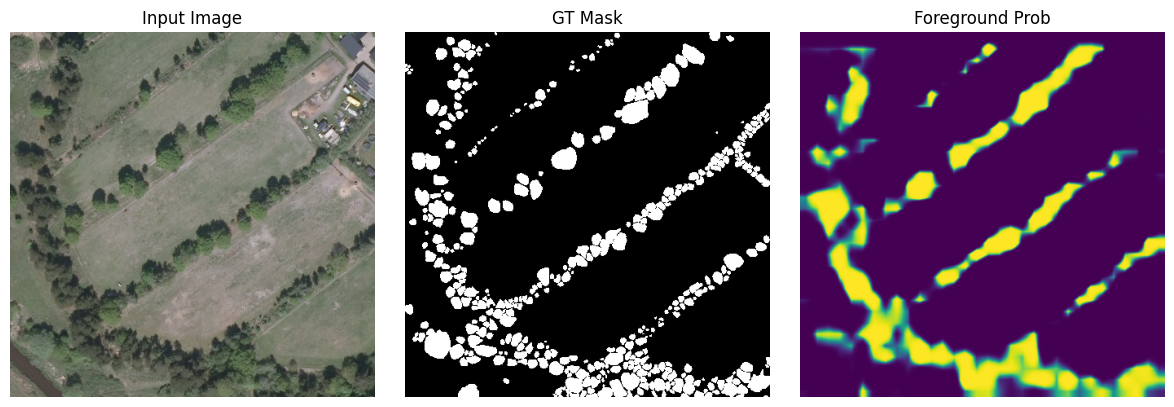

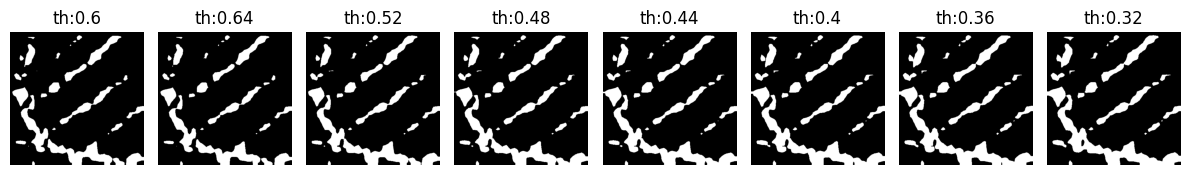

torch.Size([1, 3, 448, 448]) torch.Size([448, 448])
torch.Size([1, 2, 448, 448])


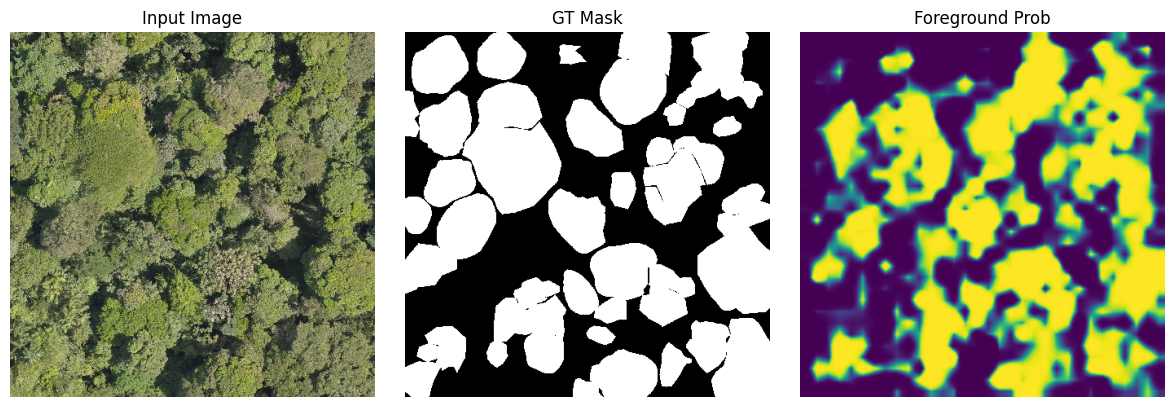

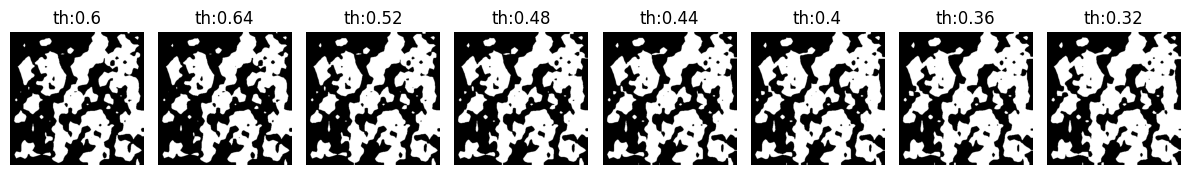

torch.Size([1, 3, 448, 448]) torch.Size([448, 448])
torch.Size([1, 2, 448, 448])


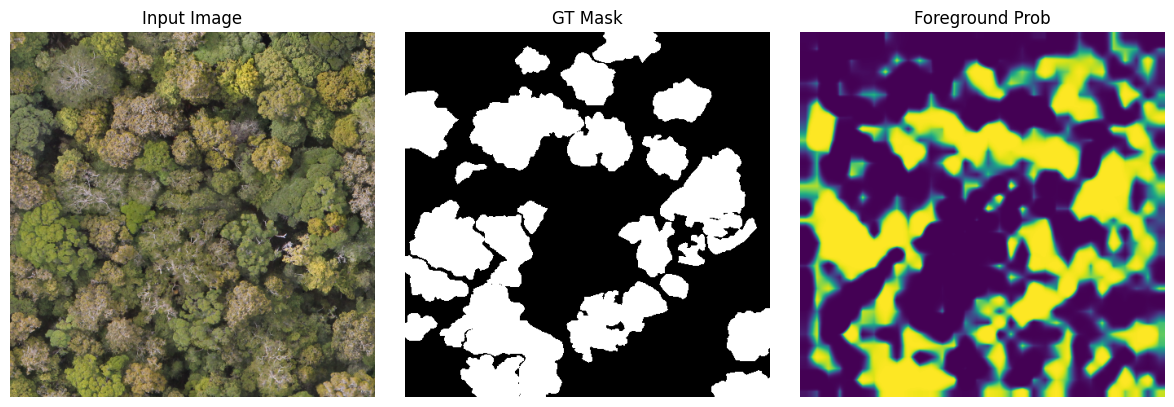

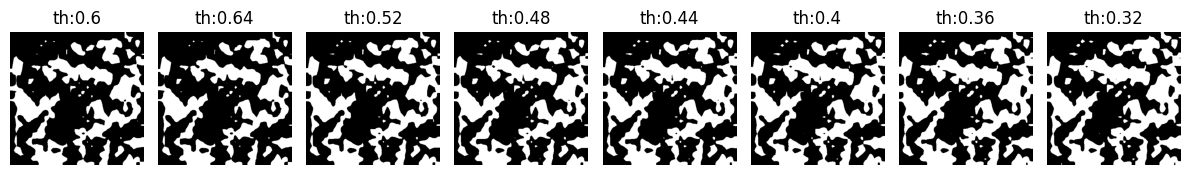

torch.Size([1, 3, 448, 448]) torch.Size([448, 448])
torch.Size([1, 2, 448, 448])


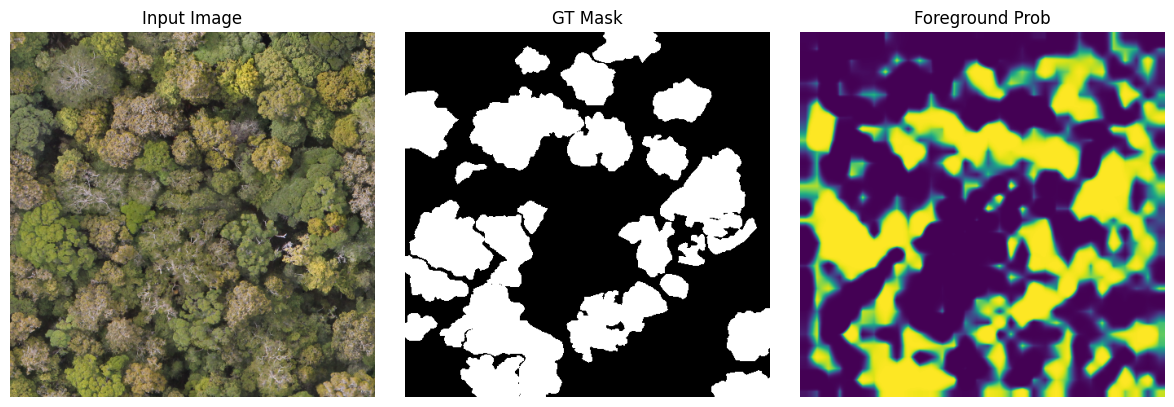

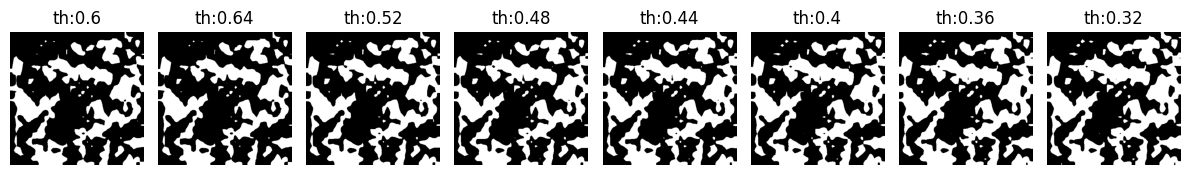

torch.Size([1, 3, 448, 448]) torch.Size([448, 448])
torch.Size([1, 2, 448, 448])


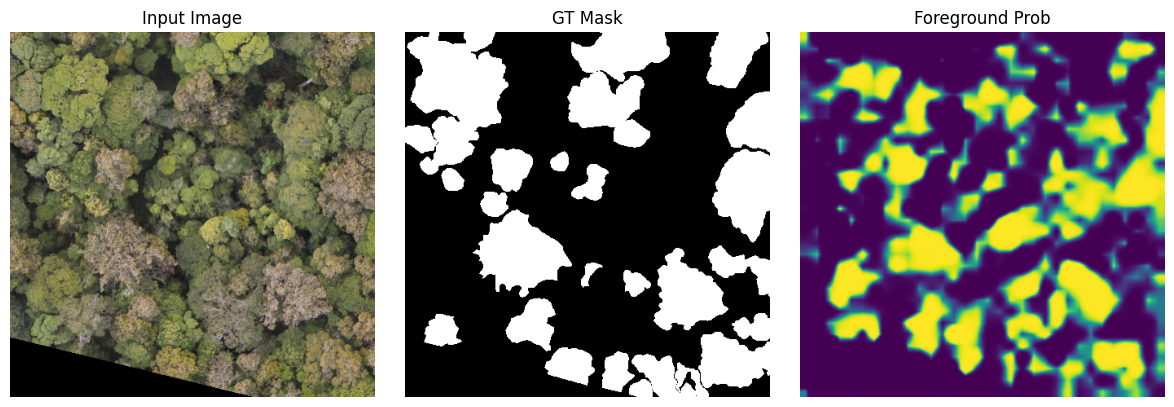

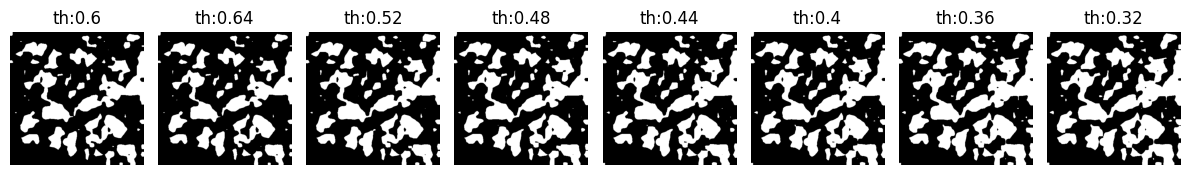

torch.Size([1, 3, 448, 448]) torch.Size([448, 448])
torch.Size([1, 2, 448, 448])


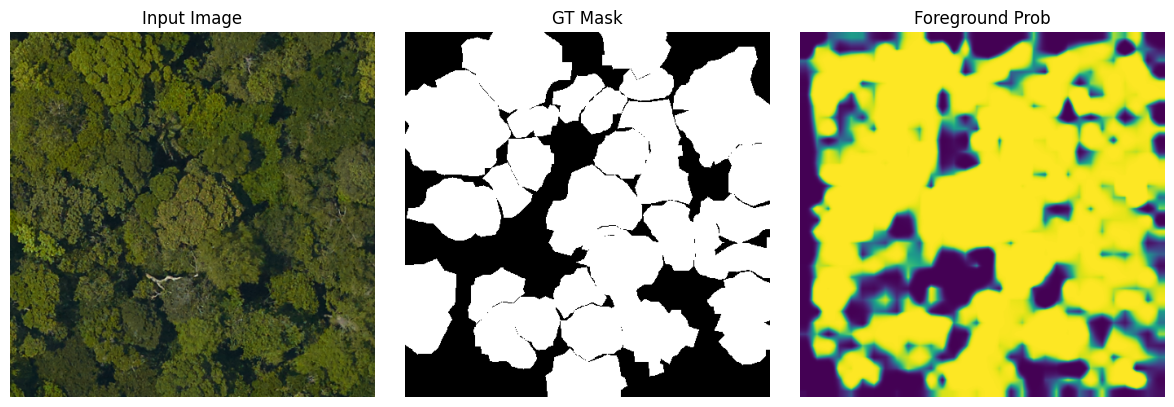

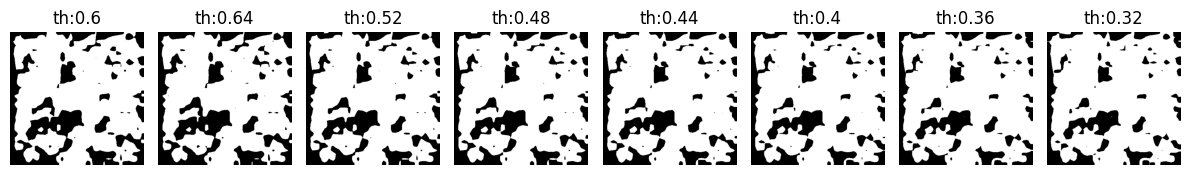

torch.Size([1, 3, 448, 448]) torch.Size([448, 448])
torch.Size([1, 2, 448, 448])


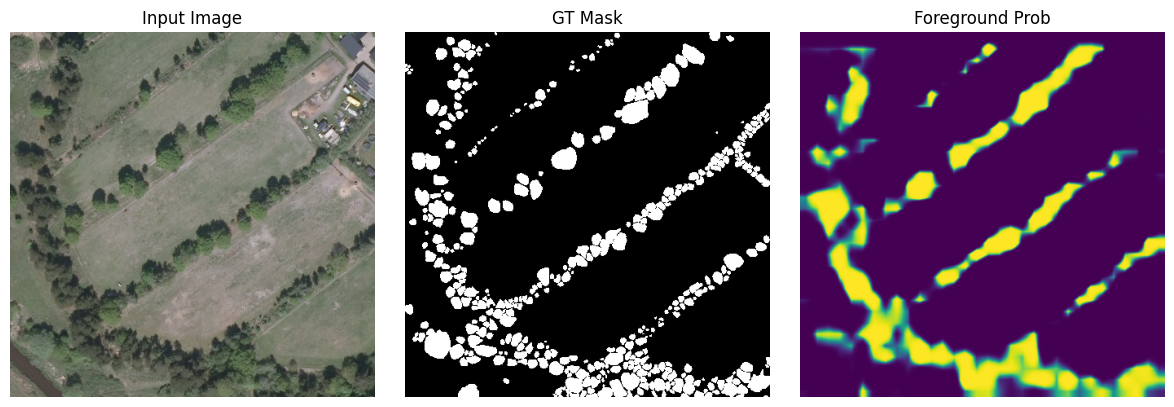

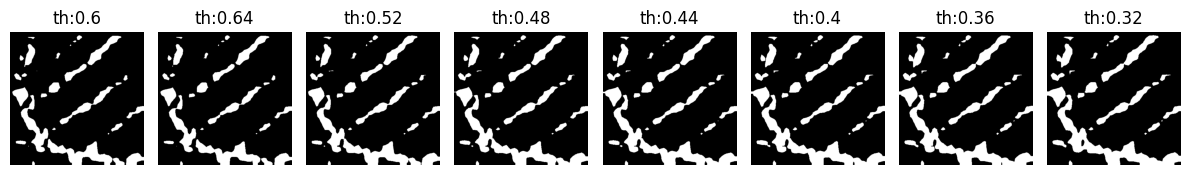

torch.Size([1, 3, 448, 448]) torch.Size([448, 448])
torch.Size([1, 2, 448, 448])


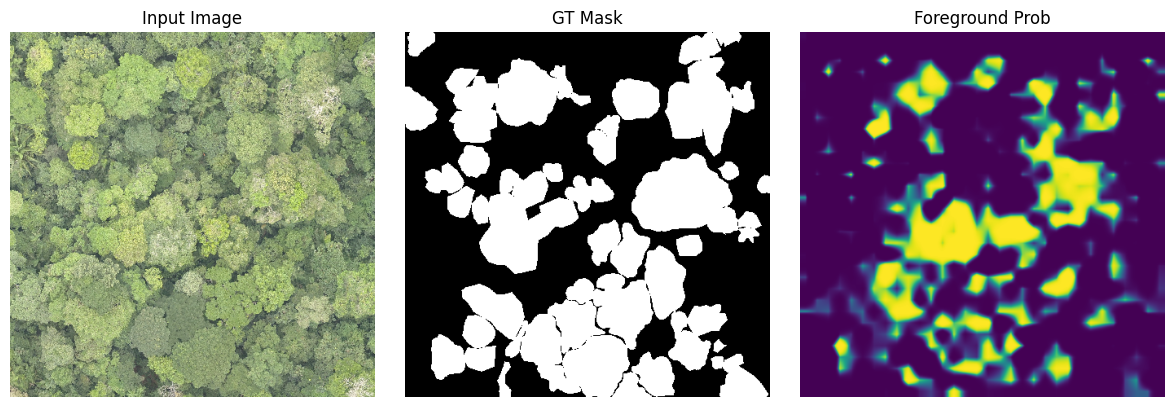

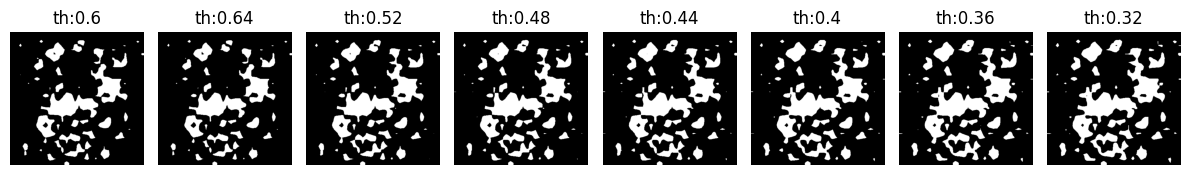

torch.Size([1, 3, 448, 448]) torch.Size([448, 448])
torch.Size([1, 2, 448, 448])


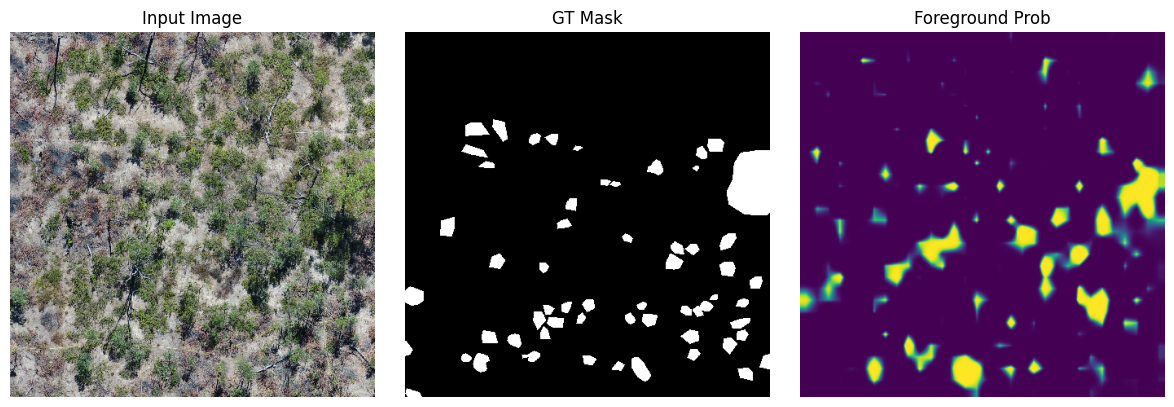

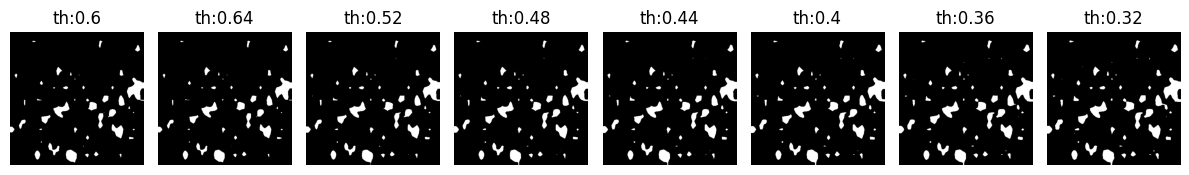

torch.Size([1, 3, 448, 448]) torch.Size([448, 448])
torch.Size([1, 2, 448, 448])


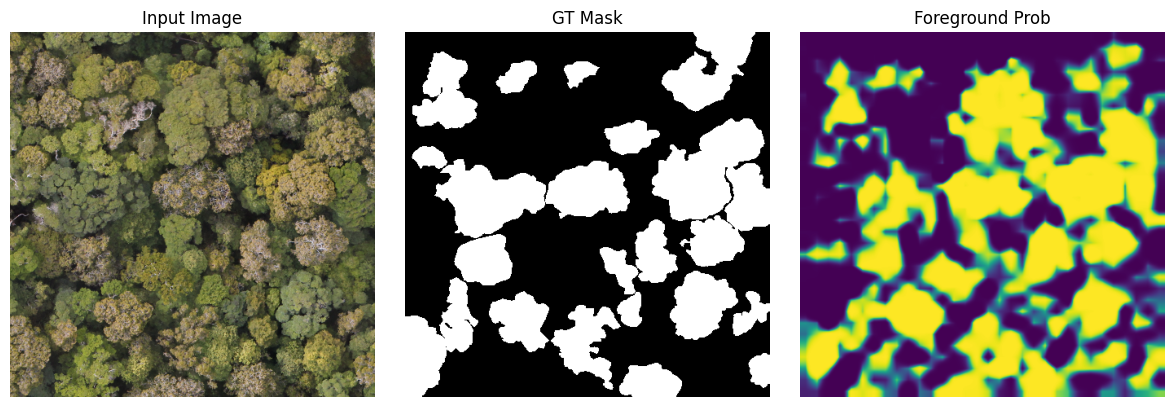

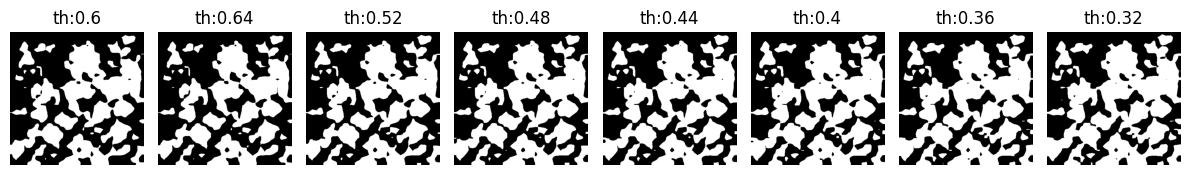

In [11]:
for i in range(10):
    idx = np.random.randint(len(train_ds))
    ## printing the filename to know which one is broken
    try:
        image, gt_mask = train_ds[idx]
    except RuntimeError:
        print(f"  → skipping idx {idx}")
        continue

    # convert to tensor batch for model
    x = image.unsqueeze(0).to(device)  # [1, 3, 448, 448]
    print(x.shape, gt_mask.shape)
    # predict
    with torch.no_grad():
        logits = model(x)             # [1, 2, 448, 448]
        print(logits.shape)
        probs = torch.softmax(logits, dim=1)[:, 1]  # foreground prob [1, 448, 448]

        # Convert to HWC for plotting
        image_np = image.permute(1, 2, 0).cpu().numpy()          # [448, 448, 3]
        gt_mask_np = gt_mask.cpu().numpy()                       # [448, 448]


    prob_np = probs.squeeze().cpu().numpy()

    fig, axes = plt.subplots(1, 3, figsize=(12, 4))

    axes[0].imshow(image_np)
    axes[0].set_title("Input Image")
    axes[0].axis("off")

    axes[1].imshow(gt_mask_np, cmap="gray")
    axes[1].set_title("GT Mask")
    axes[1].axis("off")

    axes[2].imshow(prob_np, cmap="viridis")
    axes[2].set_title("Foreground Prob")
    axes[2].axis("off")

    plt.tight_layout()
    plt.savefig(f'images/segmentation_example_{i}_proba.png')
    plt.show()

    fig, axes = plt.subplots(1, 8, figsize=(12, 4))

    for id,threshold in enumerate([0.6,0.64,0.52,0.48,0.44,0.40,0.36,0.32]):    
        pred_mask = (probs >= threshold).float().squeeze().cpu().numpy()  # [448, 448]

        # 3) predicted mask
        axes[id].imshow(pred_mask, cmap="gray")
        axes[id].set_title(f"th:{threshold}")
        axes[id].axis("off")

    plt.tight_layout()
    plt.savefig(f'images/segmentation_example_{i}_tests_th.png')
    plt.show()
